# Chapter 47: Capital Structure, Payout, and Corporate Finance

This notebook reruns four worked examples from the chapter: the pecking order of funding sources, the trade-off target for debt, the Modigliani-Miller leverage proposition and the NPV of a machine. All examples are hypothetical, as in the book; a few extra input values are added for comparison.

## Setup

The functions below are the calculations behind every number in this notebook. Run this cell first.

In [1]:
import math
from types import SimpleNamespace

import numpy as np
import matplotlib
import matplotlib.pyplot as plt



PALETTE = {
    "ink": "#172a3b",
    "teal": "#136f75",
    "gold": "#8f5d0f",
    "navy": "#334c72",
    "terracotta": "#a24a33",
    "olive": "#5d6a37",
    "grey": "#6b757b",
    "light": "#c9d3d6",
}


CYCLE = ["teal", "navy", "gold", "terracotta", "olive", "grey"]


LABEL_SIZE = 10.5


HOUSE_RC = {
    "font.size": 11.5,
    "axes.titlesize": 12,
    "axes.labelsize": 11.5,
    "xtick.labelsize": 10.5,
    "ytick.labelsize": 10.5,
    "legend.fontsize": 10.5,
    "axes.spines.top": False,
    "axes.spines.right": False,
    "axes.edgecolor": "#6b757b",
    "axes.labelcolor": "#172a3b",
    "xtick.color": "#172a3b",
    "ytick.color": "#172a3b",
    "figure.facecolor": "white",
    "axes.facecolor": "white",
    "svg.fonttype": "path",
}


def color(name_or_index):
    """Palette colour by name ('teal') or by position in the series cycle (0, 1, ...)."""
    if isinstance(name_or_index, int):
        return PALETTE[CYCLE[name_or_index % len(CYCLE)]]
    return PALETTE.get(name_or_index, name_or_index)


def tex_safe(text):
    """Escape dollar signs so Matplotlib does not read '$...$' as mathematics."""
    return str(text).replace("\\$", "$").replace("$", r"\$")


def new_figure(ncols=1, width=None, height=4.3):
    """Notebook twin of readerkit.new_figure: one panel 6.6 x 4.3 in, two panels 10.4 x 4.3 in."""
    import matplotlib.pyplot as plt

    if width is None:
        width = 6.6 if ncols == 1 else 10.4
    fig, axes = plt.subplots(1, ncols, figsize=(width, height), layout="constrained")
    for ax in (axes if ncols > 1 else [axes]):
        ax.grid(alpha=0.18)
    return fig, axes


def label(ax, x, y, text, col="ink", dx=6, dy=6, ha="left", va="bottom", box=True, size=LABEL_SIZE):
    """Direct label at data point (x, y) offset by (dx, dy) points, with a white box by default."""
    kw = {}
    if box:
        kw["bbox"] = {"boxstyle": "round,pad=0.18", "fc": "white", "ec": "none", "alpha": 0.9}
    return ax.annotate(tex_safe(text), (x, y), xytext=(dx, dy), textcoords="offset points", ha=ha, va=va,
                       color=color(col), fontsize=size, **kw)


def mark(ax, x, y, text=None, col="ink", size=42, dx=6, dy=6, ha="left", va="bottom", zorder=5):
    """Filled point with an optional direct label."""
    ax.scatter([x], [y], s=size, color=color(col), zorder=zorder)
    if text:
        label(ax, x, y, text, col=col, dx=dx, dy=dy, ha=ha, va=va)


def hline(ax, y, text=None, col="grey", style="dashed", x_frac=0.02, va="bottom", lw=1.4):
    """Horizontal reference line with an optional label at the left edge."""
    ax.axhline(y, color=color(col), linestyle=style, linewidth=lw)
    if text:
        ax.annotate(tex_safe(text), (x_frac, y), xycoords=("axes fraction", "data"), xytext=(0, 4 if va == "bottom" else -4),
                    textcoords="offset points", ha="left", va=va, color=color(col), fontsize=LABEL_SIZE,
                    bbox={"boxstyle": "round,pad=0.18", "fc": "white", "ec": "none", "alpha": 0.9})


def num(value, digits=2, comma=True):
    """Fixed-decimal string with optional thousands separators: num(1444.444) -> '1,444.44'.

    Negative zero prints as '0'. Raises ValueError on NaN or infinity, because an
    undefined value must be named in words (see ``undefined``).
    """
    value = float(value)
    if not math.isfinite(value):
        raise ValueError("non-finite value; name it with undefined(reason)")
    text = f"{value:,.{digits}f}" if comma else f"{value:.{digits}f}"
    if text.startswith("-") and float(text.replace(",", "")) == 0:
        text = text[1:]
    return text


def money(value, digits=2, comma=True):
    """Dollar amount: money(1444.444) -> '$1,444.44'; money(-480, 0) -> '-$480'."""
    text = num(value, digits, comma)
    return f"-${text[1:]}" if text.startswith("-") else f"${text}"


def pct(fraction, digits=1):
    """Percent from a fraction: pct(0.022) -> '2.2%'."""
    return f"{num(100 * float(fraction), digits)}%"


def plus(value, digits=2, comma=True):
    """Number with an explicit sign for changes: '+0.42', '-0.20', '0.00'."""
    text = num(value, digits, comma)
    return text if text.startswith("-") or float(text.replace(",", "")) == 0 else f"+{text}"


def signed(value, digits=2, comma=True):
    """Number for use inside a written sum: negatives get parentheses, '(-5.00)'."""
    text = num(value, digits, comma)
    return f"({text})" if text.startswith("-") else text


def tie_or_winner(a_name, a_value, b_name, b_value, tol=1e-9, higher_wins=True):
    """Return (winner or 'tie', is_tie). Ties within ``tol`` are reported honestly."""
    if abs(float(a_value) - float(b_value)) <= tol:
        return "tie", True
    a_better = a_value > b_value if higher_wins else a_value < b_value
    return (a_name if a_better else b_name), False


def npv(cashflows, rate):
    """Net present value of cash flows at dates 0, 1, 2, ... (capital-budgeting-npv).

    Book (ch047): cost 1,000,000, 350,000 a year for 4 years plus 100,000 salvage at 10%
    gives NPV 177,754.25 (PV 1,177,754.25); with 280,000 a year, NPV -44,136.33.
    """
    return sum(cf / (1 + rate) ** t for t, cf in enumerate(cashflows))


def npv_simple(value, cost):
    """Stand-alone NPV as value minus cost (pecking-order-theory). Book (ch047): 12 - 10 = 2."""
    return value - cost


def tradeoff_value(base, tax_benefits, distress_costs):
    """Firm value after each debt increment, list starting with the unlevered value
    (trade-off-theory-of-capital-structure). Book (ch047): 100, 104, 102 (106 with distress 2).
    """
    values = [base]
    for t, d in zip(tax_benefits, distress_costs):
        values.append(values[-1] + t - d)
    return values


def mm_prop2(rA, rD, D, E):
    """Required equity return r_E = r_A + (D/E)(r_A - r_D) (modigliani-miller-leverage-proposition).

    Book (ch047): r_A 8%, r_D 4%, D = E = 50 gives 12%; D = 75, E = 25 gives 20%.
    """
    return rA + (D / E) * (rA - rD)


def wacc(rE, rD, D, E):
    """Value-weighted return E/V r_E + D/V r_D, no taxes (modigliani-miller-leverage-proposition).

    Book (ch047): (50/100)(12%) + (50/100)(4%) = 8%.
    """
    V = D + E
    return E / V * rE + D / V * rD


plt.rcParams.update(HOUSE_RC)


finance = SimpleNamespace(npv=npv, npv_simple=npv_simple, tradeoff_value=tradeoff_value, mm_prop2=mm_prop2, wacc=wacc)


# The book's printed values for this chapter (inputs of the worked examples).
BV = {'pecking-order-theory': {'cost': 10,
                          'value': 12,
                          'npv': 2,
                          'price': 0.75,
                          'claims': 13.33,
                          'transfer': 3.33},
 'trade-off-theory-of-capital-structure': {'base': 100,
                                           'tax1': 5,
                                           'distress1': 1,
                                           'tax2': 4,
                                           'distress2': 6,
                                           'distress2_guarantee': 2,
                                           'V1': 104,
                                           'V2': 102,
                                           'V2_guarantee': 106},
 'modigliani-miller-leverage-proposition': {'V': 100,
                                            'rA': 0.08,
                                            'rD': 0.04,
                                            'income': 8,
                                            'D': 50,
                                            'rE': 0.12,
                                            'wacc': 0.08,
                                            'debt_income': 2,
                                            'equity_income': 6,
                                            'D_2': 75,
                                            'rE_2': 0.2,
                                            'debt_income_2': 3,
                                            'equity_income_2': 5},
 'capital-budgeting-npv': {'cost': 1000000,
                           'cf': 350000,
                           'salvage': 100000,
                           'r': 0.1,
                           'life': 4,
                           'pv': 1177754.25,
                           'npv': 177754.25,
                           'cf_2': 280000,
                           'pv_2': 955863.67,
                           'npv_2': -44136.33},
 'constructed': {'pecking-order-theory': {'prices': [0.85, 0.9, 1.0]},
                 'trade-off-theory-of-capital-structure': {'distress2': [4, 8], 'tax2': [2, 6]},
                 'modigliani-miller-leverage-proposition': {'D': [0, 25], 'rD': [0.03, 0.05]},
                 'capital-budgeting-npv': {'cf': [315000], 'r': [0.08, 0.12, 0.14]}}}


SOURCE_NAMES = {"equity": "new equity", "cash": "retained cash", "debt": "safe debt"}


def pecking_picture(price=0.75, source="equity"):
    npv = finance.npv_simple(12, 10)
    if source == "equity":
        claims = 10 / price
        transfer = claims - 10
    else:
        claims, transfer = 10.0, 0.0
    net = npv - transfer
    fig, ax = new_figure()
    names = ["Project NPV", "Transfer to new holders", "Old holders' net"]
    vals = [npv, -transfer, net]
    cols = [PALETTE["teal"], PALETTE["terracotta"] if transfer > 0 else PALETTE["grey"],
            PALETTE["olive"] if net > 1e-9 else PALETTE["terracotta"]]
    xs = np.arange(3)
    ax.bar(xs, vals, color=cols, width=0.55)
    ax.axhline(0, color=PALETTE["grey"], linewidth=1)
    for x, v in zip(xs, vals):
        ax.annotate(num(v), (x, v), xytext=(0, 5 if v >= 0 else -5), textcoords="offset points", ha="center",
                    va="bottom" if v >= 0 else "top", fontsize=11, color=PALETTE["ink"])
    ax.set_xticks(xs, names)
    ax.set_ylim(-4.2, 3.0)
    ax.set_ylabel("Million dollars")
    ax.set_xlabel(f"Funding source: {SOURCE_NAMES[source]}")
    accept = net > 1e-9
    verdict = "accept" if accept else "reject"
    metrics = {"Project NPV": num(npv), "Claims sold (true value)": num(claims),
               "Transfer to new holders": num(transfer), "Old holders' net": num(net),
               "Old shareholders": verdict}
    if source == "equity":
        interp = (f"NPV = 12 - 10 = {num(npv)}. Outsiders pay {num(price)} per dollar of true value, so raising 10 "
                  f"million means selling claims worth 10 / {num(price)} = {num(claims)} million. The transfer is "
                  f"{num(claims)} - 10 = {num(transfer)}, and old holders net {num(npv)} - {num(transfer)} = "
                  f"{num(net)}, so they {verdict} the project. Break-even price: 10 / 12 = 0.83.")
        steps = [f"NPV = 12 - 10 = {num(npv)}", f"Claims = 10 / {num(price)} = {num(claims)}",
                 f"Transfer = {num(claims)} - 10 = {num(transfer)}",
                 f"Net = {num(npv)} - {num(transfer)} = {num(net)}: {verdict}"]
    else:
        interp = (f"With {SOURCE_NAMES[source]} there is no underpriced stock to sell, so the transfer is 0 and old "
                  f"holders keep the whole NPV of 12 - 10 = {num(npv)}. They accept, whatever outsiders would pay "
                  f"for equity ({num(price)}).")
        steps = [f"NPV = 12 - 10 = {num(npv)}", "Transfer = 0", f"Net = {num(npv)} - 0 = {num(net)}: accept"]
    alt = (f"Bars for project NPV {num(npv)}, transfer {num(transfer)} and old holders' net {num(net)} million "
           f"when the project is funded with {SOURCE_NAMES[source]} at an outsider price of {num(price)}.")
    return fig, metrics, interp, {"alt": alt, "steps": steps}


def tradeoff_picture(distress2=6, tax2=4):
    V = finance.tradeoff_value(100, [5, tax2], [1, distress2])
    winner, tie = tie_or_winner("two", V[2], "one", V[1])
    fig, ax = new_figure()
    ax.plot([0, 1, 2], V, color=PALETTE["navy"], linewidth=2.2, marker="o")
    for i, v in enumerate(V):
        label(ax, i, v, num(v, 0), col="navy", dx=0, dy=9, ha="center")
    best = 1 if winner == "one" or tie else 2
    mark(ax, best, V[best], None, col="gold", size=150, zorder=4)
    ax.set_xticks([0, 1, 2], ["No debt", "One increment", "Two increments"])
    ax.set_xlim(-0.4, 2.4)
    ax.set_ylim(96, 112)
    ax.set_ylabel("Firm value (million dollars)")
    ax.set_xlabel("Debt level")
    change = V[2] - V[1]
    target = "one or two increments (tie)" if tie else ("one increment" if winner == "one" else "two increments")
    metrics = {"Value with no debt": num(V[0], 0), "Value after one increment": num(V[1], 0),
               "Value after two increments": num(V[2], 0), "Change from the second increment": plus(change, 0),
               "Debt target": target}
    verdict = ("The second increment exactly breaks even, so the firm is indifferent." if tie else
               "The second increment destroys value, so the target is one increment." if winner == "one" else
               "The second increment adds value, so the target moves to two increments.")
    interp = (f"V1 = 100 + 5 - 1 = {num(V[1], 0)}. V2 = {num(V[1], 0)} + {tax2} - {distress2} = {num(V[2], 0)}, a "
              f"change of {plus(change, 0)}. {verdict}")
    steps = [f"V1 = 100 + 5 - 1 = {num(V[1], 0)}", f"V2 = {num(V[1], 0)} + {tax2} - {distress2} = {num(V[2], 0)}",
             f"Marginal effect = {tax2} - {distress2} = {plus(change, 0)}", f"Target: {target}"]
    alt = (f"Firm value at no debt, one and two increments: {num(V[0], 0)}, {num(V[1], 0)} and {num(V[2], 0)} "
           f"million, with the target at {target}.")
    return fig, metrics, interp, {"alt": alt, "steps": steps}


def mm_picture(debt=50, rd=0.04):
    rA, V = 0.08, 100
    E = V - debt
    rE = finance.mm_prop2(rA, rd, debt, E)
    w = finance.wacc(rE, rd, debt, E)
    debt_inc = rd * debt
    eq_inc = rA * V - debt_inc
    fig, (ax1, ax2) = new_figure(ncols=2)
    xs = np.arange(4)
    levels = [0, 25, 50, 75]
    d_inc = [rd * d for d in levels]
    e_inc = [8 - x for x in d_inc]
    ax1.bar(xs, e_inc, color=PALETTE["teal"], width=0.55, label="equity income")
    ax1.bar(xs, d_inc, bottom=e_inc, color=PALETTE["gold"], width=0.55, label="debt income")
    i = levels.index(debt)
    ax1.bar([i], [8], color="none", edgecolor=PALETTE["ink"], linewidth=2, width=0.6)
    ax1.set_xticks(xs, [str(d) for d in levels])
    ax1.set_ylim(0, 11)
    ax1.set_xlabel("Debt (million dollars)")
    ax1.set_ylabel("Expected income (million dollars)")
    ax1.legend(loc="upper left", frameon=False, ncol=2)
    de = np.linspace(0, 3.2, 100)
    ax2.plot(de, 100 * (rA + de * (rA - rd)), color=PALETTE["navy"], linewidth=2.2, label="equity return")
    ax2.axhline(100 * rA, color=PALETTE["grey"], linestyle="dashed", linewidth=1.4, label="asset return and WACC")
    if debt / E < 1.5:
        mark(ax2, debt / E, 100 * rE, pct(rE, 2), col="navy", dx=10, dy=-8, ha="left", va="top")
    else:
        mark(ax2, debt / E, 100 * rE, pct(rE, 2), col="navy", dx=-8, dy=6, ha="right")
    ax2.set_xlim(0, 3.2)
    ax2.set_ylim(0, 30)
    ax2.set_xlabel("Debt to equity D/E")
    ax2.set_ylabel(tex_safe("Return (%)"))
    ax2.legend(loc="upper left", frameon=False)
    de_val = debt / E
    dd = 2 if abs(100 * de_val - round(100 * de_val)) < 1e-9 else 4
    metrics = {"D/E": num(de_val), "Equity return": pct(rE, 2), "Debt income": num(debt_inc),
               "Equity income": num(eq_inc), "WACC": pct(w, 2)}
    interp = (f"With debt {debt} and equity {E}, D/E = {debt}/{E} = {num(de_val, dd)}. r_E = 8% + {num(de_val, dd)}(8% - "
              f"{pct(rd, 0)}) = {pct(rE, 2)}. Creditors get {pct(rd, 0)} x {debt} = {num(debt_inc)}, equity gets 8 - "
              f"{num(debt_inc)} = {num(eq_inc)}. The weighted return stays {pct(w, 2)}: leverage shifts the split, "
              f"not the total.")
    steps = [f"D/E = {debt} / {E} = {num(de_val, dd)}", f"r_E = 8% + {num(de_val, dd)} x (8% - {pct(rd, 0)}) = {pct(rE, 2)}",
             f"Debt income = {num(rd)} x {debt} = {num(debt_inc)}; equity income = 8 - {num(debt_inc)} = {num(eq_inc)}",
             f"WACC = ({E}/100)({pct(rE, 2)}) + ({debt}/100)({pct(rd, 0)}) = {pct(w, 2)}"]
    alt = (f"Left: 8 million of income split into debt and equity income at each debt level. Right: equity return "
           f"rising with D/E; at debt {debt} it is {pct(rE, 2)} while the weighted return stays {pct(w, 2)}.")
    return fig, metrics, interp, {"alt": alt, "steps": steps}


def _parts(cf, r):
    """Annuity factor, annuity PV, salvage PV and total with display digits that add up."""
    af = (1 - (1 + r) ** -4) / r
    ann = cf * af
    salv = 100_000 / (1 + r) ** 4
    pv = ann + salv
    def f(x, n):
        return float(num(x, n, comma=False))
    for d in (2, 3, 4):
        if num(f(ann, d) + f(salv, d)) == num(pv):
            break
    for k in (6, 7, 8, 9, 10, 11, 12):
        if num(cf * f(af, k), d) == num(ann, d):
            break
    return af, k, ann, salv, pv, d


def npv_picture(cf=350_000, r=0.10):
    flows = [-1_000_000, cf, cf, cf, cf + 100_000]
    npv = finance.npv(flows, r)
    af, k, ann, salv, pv, d = _parts(cf, r)
    disc = [flows[t] / (1 + r) ** t for t in range(1, 5)]
    cum = np.cumsum(disc)
    fig, ax = new_figure()
    years = np.arange(1, 5)
    ax.bar(years, np.array(disc) / 1000, color=PALETTE["teal"], width=0.55, label="discounted cash flow")
    ax.plot(years, cum / 1000, color=PALETTE["navy"], marker="o", linewidth=2.2, label="cumulative PV")
    hline(ax, 1000, "cost 1,000,000", col="terracotta", x_frac=0.02)
    near = abs(cum[-1] / 1000 - 1000) < 60
    label(ax, 4, cum[-1] / 1000, f"PV {num(pv)}", col="navy", dx=-8, dy=(-10 if near and pv < 1e6 else 8),
          ha="right", **({"va": "top"} if near and pv < 1e6 else {}))
    ax.set_xticks(years, [f"Year {y}" for y in years])
    ax.set_ylim(0, 1400)
    ax.set_xlim(0.4, 4.6)
    ax.set_ylabel("Thousand dollars")
    ax.set_xlabel("Year")
    ax.legend(loc="upper left", frameon=False)
    decision = "accept" if npv > 0 else "reject"
    metrics = {"Present value": num(pv), "NPV": num(npv), "Decision": decision,
               "Annuity factor": num(af, 4)}
    interp = (f"The annuity factor at {pct(r, 0)} for 4 years is {num(af, k)}, so the operating flows are worth "
              f"{num(cf, 0)} x {num(af, k)} = {num(ann, d)}. Salvage is worth 100,000 / {num(1 + r)}^4 = "
              f"{num(salv, d)}. PV = {num(pv)} and NPV = {num(pv)} - 1,000,000 = {num(npv)}, so {decision}.")
    steps = [f"Annuity factor = (1 - {num(1 + r)}^-4) / {num(r)} = {num(af, k)}",
             f"{num(cf, 0)} x {num(af, k)} = {num(ann, d)}",
             f"100,000 / {num(1 + r)}^4 = {num(salv, d)}",
             f"PV = {num(ann, d)} + {num(salv, d)} = {num(pv)}",
             f"NPV = {num(pv)} - 1,000,000 = {num(npv)}: {decision}"]
    alt = (f"Discounted cash flows for years 1 to 4 and the cumulative present value, which ends at {num(pv)} "
           f"against the 1,000,000 cost line; NPV {num(npv)}, {decision}.")
    return fig, metrics, interp, {"alt": alt, "steps": steps}

def show(result):
    """Draw the figure, then print the numbers, the worked steps and the reading."""
    fig, metrics, interpretation = result[0], result[1], result[2]
    extra = result[3] if len(result) > 3 else {}
    plt.show()
    width = max(len(k) for k in metrics)
    for k, v in metrics.items():
        print(f"{k:<{width}}  {v}")
    steps = extra.get("steps", []) if isinstance(extra, dict) else []
    if steps:
        print("\nWorked steps:")
        for i, s in enumerate(steps, 1):
            print(f"  {i}. {s}")
    print("\n" + interpretation)


def sweep(function, control, values, fixed, labels):
    """One line per value of one input, holding the others fixed."""
    print(" | ".join([control] + labels))
    for v in values:
        result = function(**{**fixed, control: v})
        plt.close(result[0])
        print(" | ".join([str(v)] + [str(result[1][k]) for k in labels]))


## 1. Pecking-order theory

A project costs 10 million dollars and is worth 12 million. Outsiders pay 0.75 per dollar of true equity value.

$$\frac{10}{0.75}=13.333\ldots\text{ million dollars},\qquad 13.333-10=3.333\text{ million dollars}$$

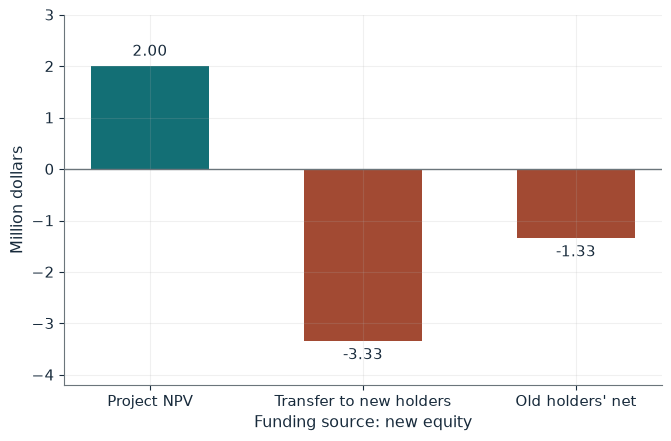

Project NPV               2.00
Claims sold (true value)  13.33
Transfer to new holders   3.33
Old holders' net          -1.33
Old shareholders          reject

Worked steps:
  1. NPV = 12 - 10 = 2.00
  2. Claims = 10 / 0.75 = 13.33
  3. Transfer = 13.33 - 10 = 3.33
  4. Net = 2.00 - 3.33 = -1.33: reject

NPV = 12 - 10 = 2.00. Outsiders pay 0.75 per dollar of true value, so raising 10 million means selling claims worth 10 / 0.75 = 13.33 million. The transfer is 13.33 - 10 = 3.33, and old holders net 2.00 - 3.33 = -1.33, so they reject the project. Break-even price: 10 / 12 = 0.83.


In [2]:
show(pecking_picture(price=0.75, source='equity'))

Change one input, `price`, and hold the others at the book's values:

In [3]:
sweep(pecking_picture, 'price', [0.75, 0.85, 0.9, 1.0], {'source': 'equity'}, ['Transfer to new holders', "Old holders' net", 'Old shareholders'])

price | Transfer to new holders | Old holders' net | Old shareholders
0.75 | 3.33 | -1.33 | reject
0.85 | 1.76 | 0.24 | accept
0.9 | 1.11 | 0.89 | accept
1.0 | 0.00 | 2.00 | accept


At 0.75 the transfer of 3.33 exceeds the NPV of 2, so old holders reject. From 0.85 up the transfer falls below 2 and they accept. Retained cash or safe debt avoids the transfer.

## 2. Trade-off theory of capital structure

$$100+5-1=104\text{ million dollars},\qquad 104+4-6=102\text{ million dollars}$$

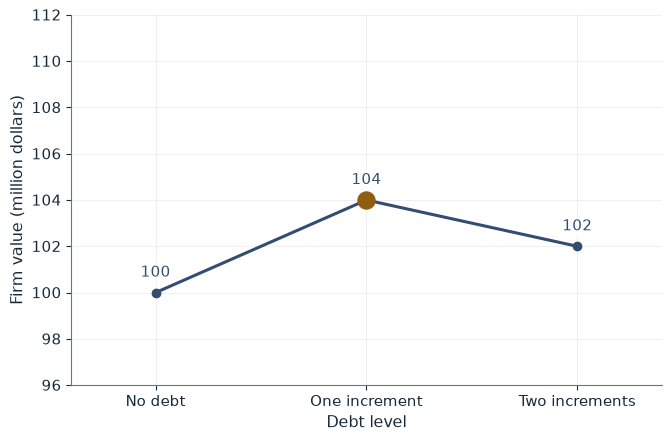

Value with no debt                100
Value after one increment         104
Value after two increments        102
Change from the second increment  -2
Debt target                       one increment

Worked steps:
  1. V1 = 100 + 5 - 1 = 104
  2. V2 = 104 + 4 - 6 = 102
  3. Marginal effect = 4 - 6 = -2
  4. Target: one increment

V1 = 100 + 5 - 1 = 104. V2 = 104 + 4 - 6 = 102, a change of -2. The second increment destroys value, so the target is one increment.


In [4]:
show(tradeoff_picture(distress2=6, tax2=4))

Change one input, `distress2`, and hold the others at the book's values:

In [5]:
sweep(tradeoff_picture, 'distress2', [2, 4, 6, 8], {'tax2': 4}, ['Value after two increments', 'Change from the second increment', 'Debt target'])

distress2 | Value after two increments | Change from the second increment | Debt target
2 | 106 | +2 | two increments
4 | 104 | 0 | one or two increments (tie)
6 | 102 | -2 | one increment
8 | 100 | -4 | one increment


With a distress cost of 6 the second slice loses 2, so the target is one increment; the guarantee case (2) gives 106 and moves the target to two increments; at 4 the firm is indifferent.

## 3. Modigliani-Miller leverage proposition

$$r_E=8\%+\frac{50}{50}(8\%-4\%)=12\%,\qquad \frac{50}{100}(12\%)+\frac{50}{100}(4\%)=8\%$$

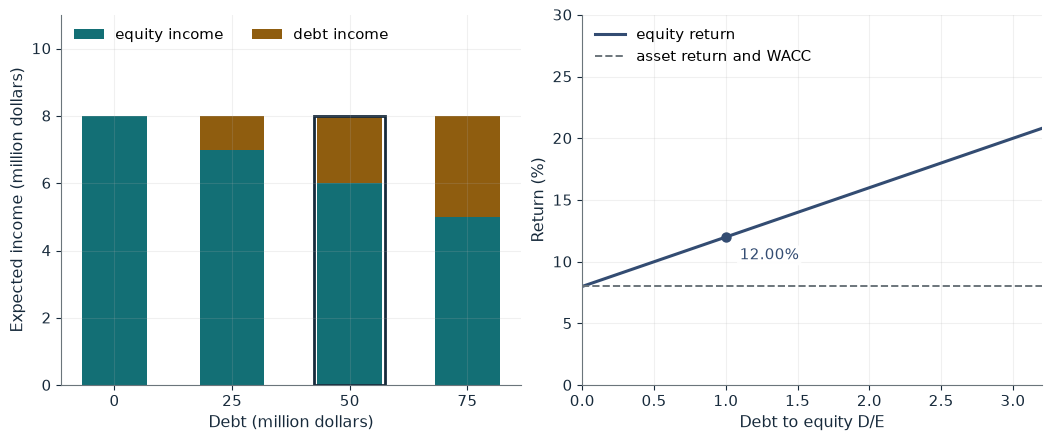

D/E            1.00
Equity return  12.00%
Debt income    2.00
Equity income  6.00
WACC           8.00%

Worked steps:
  1. D/E = 50 / 50 = 1.00
  2. r_E = 8% + 1.00 x (8% - 4%) = 12.00%
  3. Debt income = 0.04 x 50 = 2.00; equity income = 8 - 2.00 = 6.00
  4. WACC = (50/100)(12.00%) + (50/100)(4%) = 8.00%

With debt 50 and equity 50, D/E = 50/50 = 1.00. r_E = 8% + 1.00(8% - 4%) = 12.00%. Creditors get 4% x 50 = 2.00, equity gets 8 - 2.00 = 6.00. The weighted return stays 8.00%: leverage shifts the split, not the total.


In [6]:
show(mm_picture(debt=50, rd=0.04))

Change one input, `debt`, and hold the others at the book's values:

In [7]:
sweep(mm_picture, 'debt', [0, 25, 50, 75], {'rd': 0.04}, ['D/E', 'Equity return', 'WACC'])

debt | D/E | Equity return | WACC
0 | 0.00 | 8.00% | 8.00%
25 | 0.33 | 9.33% | 8.00%
50 | 1.00 | 12.00% | 8.00%
75 | 3.00 | 20.00% | 8.00%


The equity return rises from 8% to 9.33%, 12% and 20% as debt grows, while the weighted return stays at 8%: the 8 million of income is only split differently.

## 4. Capital budgeting and NPV

$$PV=\sum_{t=1}^{4}\frac{350{,}000}{1.10^t}+\frac{100{,}000}{1.10^4}\approx1{,}177{,}754.25\text{ dollars}$$

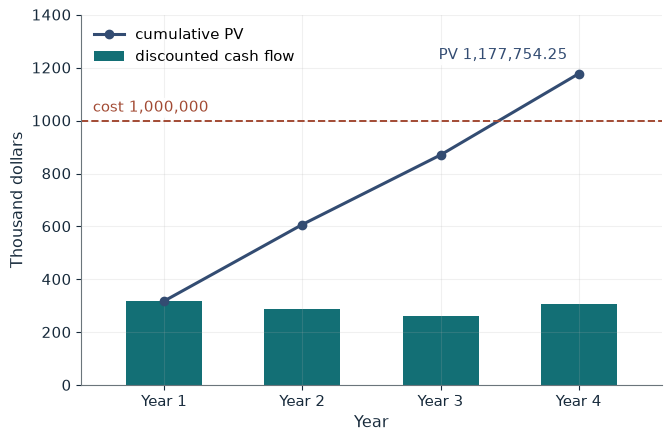

Present value   1,177,754.25
NPV             177,754.25
Decision        accept
Annuity factor  3.1699

Worked steps:
  1. Annuity factor = (1 - 1.10^-4) / 0.10 = 3.169865446
  2. 350,000 x 3.169865446 = 1,109,452.906
  3. 100,000 / 1.10^4 = 68,301.346
  4. PV = 1,109,452.906 + 68,301.346 = 1,177,754.25
  5. NPV = 1,177,754.25 - 1,000,000 = 177,754.25: accept

The annuity factor at 10% for 4 years is 3.169865446, so the operating flows are worth 350,000 x 3.169865446 = 1,109,452.906. Salvage is worth 100,000 / 1.10^4 = 68,301.346. PV = 1,177,754.25 and NPV = 1,177,754.25 - 1,000,000 = 177,754.25, so accept.


In [8]:
show(npv_picture(cf=350_000, r=0.10))

Change one input, `cf`, and hold the others at the book's values:

In [9]:
sweep(npv_picture, 'cf', [280000, 315000, 350000], {'r': 0.1}, ['Present value', 'NPV', 'Decision'])

cf | Present value | NPV | Decision
280000 | 955,863.67 | -44,136.33 | reject
315000 | 1,066,808.96 | 66,808.96 | accept
350000 | 1,177,754.25 | 177,754.25 | accept


At 350,000 a year the NPV is 177,754.25 and the machine is bought; at 280,000 it falls to -44,136.33 and the decision reverses.

## Your numbers

Replace the inputs below with your own and run the cell. Every function above accepts any value in the range its section describes.

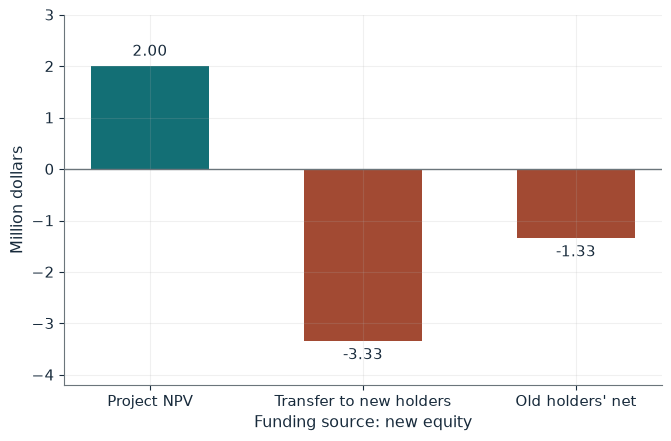

Project NPV               2.00
Claims sold (true value)  13.33
Transfer to new holders   3.33
Old holders' net          -1.33
Old shareholders          reject

Worked steps:
  1. NPV = 12 - 10 = 2.00
  2. Claims = 10 / 0.75 = 13.33
  3. Transfer = 13.33 - 10 = 3.33
  4. Net = 2.00 - 3.33 = -1.33: reject

NPV = 12 - 10 = 2.00. Outsiders pay 0.75 per dollar of true value, so raising 10 million means selling claims worth 10 / 0.75 = 13.33 million. The transfer is 13.33 - 10 = 3.33, and old holders net 2.00 - 3.33 = -1.33, so they reject the project. Break-even price: 10 / 12 = 0.83.


In [10]:
show(pecking_picture(price=0.75, source='equity'))

## Practice

**1.** If the outsider price were 0.85, would managers issue equity for the project?

<details><summary>Answer</summary>

10 / 0.85 = 11.76, so the transfer is 1.76 < 2 and old holders net +0.24: yes.

</details>

**2.** With debt 25 and r_D = 4%, what is r_E?

<details><summary>Answer</summary>

D/E = 25/75 = 1/3, so r_E = 8% + (1/3)(4%) = 9.33%; equity income 7 / 75 = 9.33%.

</details>

**3.** At 350,000 per year and 14%, accept or reject the machine?

<details><summary>Answer</summary>

350,000 x 2.913712 = 1,019,799 plus 100,000 / 1.14^4 = 59,208 gives PV 1,079,007 and NPV 79,007: accept.

</details>